# 72-hour PM2.5 Regression Learning Notebook

This notebook uses simple regression methods to learn future PM2.5 values.

The models are:

1. **Ridge Regression** - a better regularized linear model
2. **Random Forest Regressor** - a stronger non-linear model

The goal is to predict 18 four-hour PM2.5 values, covering the next 72 hours.

This notebook is for learning only. It does not save or replace the project production model.

In [25]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_PATH = PROJECT_ROOT / 'data' / 'processed' / 'master_multi_city_4h.parquet'

print('Data file:', DATA_PATH)

Data file: c:\Users\ANISH\OneDrive\Desktop\SEM 5\ML\cp\data\processed\master_multi_city_4h.parquet


## 1. Load and inspect the data

In [26]:
df = pd.read_parquet(DATA_PATH)
df['time_4h'] = pd.to_datetime(df['time_4h'])
df = df.sort_values(['city_id', 'time_4h']).reset_index(drop=True)

print('Rows:', len(df))
print('Cities:', df['city_id'].nunique())
print('Time range:', df['time_4h'].min(), 'to', df['time_4h'].max())
print('Missing PM2.5 values:', df['pm2_5'].isna().sum())

Rows: 131520
Cities: 20
Time range: 2023-01-01 00:00:00 to 2025-12-31 20:00:00
Missing PM2.5 values: 0


## 2. Create useful input features

Only information available before the forecast is used. Future PM2.5 is never used as an input.

In [27]:
data = df.copy()
g = data.groupby('city_id')

# Pollution history
for lag in [1, 2, 3, 6, 12, 18]:
    data[f'pm25_lag_{lag}'] = g['pm2_5'].shift(lag)

for window in [3, 6, 12]:
    data[f'pm25_mean_{window}'] = g['pm2_5'].transform(lambda s, w=window: s.shift(1).rolling(w).mean())
    data[f'pm25_std_{window}'] = g['pm2_5'].transform(lambda s, w=window: s.shift(1).rolling(w).std())

data['pm25_change_6'] = data['pm25_lag_1'] - data['pm25_lag_6']
data['pm25_change_12'] = data['pm25_lag_1'] - data['pm25_lag_12']

# Weather history
for col in ['temp', 'humidity', 'surface_pressure', 'wind_speed', 'pm10', 'nitrogen_dioxide', 'ozone']:
    data[f'{col}_lag1'] = g[col].shift(1)

# Time features
data['hour'] = data['time_4h'].dt.hour
data['month'] = data['time_4h'].dt.month
data['hour_sin'] = np.sin(2 * np.pi * data['hour'] / 24)
data['hour_cos'] = np.cos(2 * np.pi * data['hour'] / 24)
data['month_sin'] = np.sin(2 * np.pi * data['month'] / 12)
data['month_cos'] = np.cos(2 * np.pi * data['month'] / 12)

print('Total engineered columns:', len(data.columns))

Total engineered columns: 49


## 3. Create 18 future PM2.5 targets

- `target_1` = 4 hours ahead
- `target_18` = 72 hours ahead

In [28]:
HORIZONS = 18

for h in range(1, HORIZONS + 1):
    data[f'target_{h}'] = g['pm2_5'].shift(-h)

target_cols = [f'target_{h}' for h in range(1, HORIZONS + 1)]

feature_cols = ['city_id', 'pm2_5', 'pm25_lag_1', 'pm25_lag_2', 'pm25_lag_3',
                'pm25_lag_6', 'pm25_lag_12', 'pm25_lag_18',
                'pm25_mean_3', 'pm25_std_3', 'pm25_mean_6', 'pm25_std_6',
                'pm25_mean_12', 'pm25_std_12', 'pm25_change_6', 'pm25_change_12',
                'temp', 'humidity', 'surface_pressure', 'wind_speed', 'wind_u', 'wind_v',
                'pm10', 'nitrogen_dioxide', 'ozone',
                'temp_lag1', 'humidity_lag1', 'surface_pressure_lag1', 'wind_speed_lag1',
                'pm10_lag1', 'nitrogen_dioxide_lag1', 'ozone_lag1',
                'hour_sin', 'hour_cos', 'month_sin', 'month_cos']

model_data = data.dropna(subset=feature_cols + target_cols).copy()

print('Usable rows:', len(model_data))
print('Input features:', len(feature_cols))
print('Output targets:', len(target_cols))

Usable rows: 130800
Input features: 36
Output targets: 18


## 4. Chronological train/test split

The training set contains older data. The test set contains later data and is never used for fitting.

In [29]:
train_end = pd.Timestamp('2024-12-31 23:59:59')

train = model_data[model_data['time_4h'] <= train_end]
test = model_data[model_data['time_4h'] > train_end]

X_train = train[feature_cols]
y_train = train[target_cols]
X_test = test[feature_cols]
y_test = test[target_cols]

print('Training rows:', len(train))
print('Testing rows:', len(test))
print('Test period:', test['time_4h'].min(), 'to', test['time_4h'].max())

Training rows: 87360
Testing rows: 43440
Test period: 2025-01-01 00:00:00 to 2025-12-28 20:00:00


## 5. Ridge Regression

Ridge is a regularized Linear Regression model. Regularization helps stop the model from becoming too sensitive to noise.

Ridge Regularization (L2)

It adds an L2 penalty (lambda m^2), to linear regression’s loss function. It shrinks large coefficients, reducing overfitting and handling correlated features. 

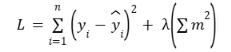

In [30]:
categorical = ['city_id']
numeric = [c for c in feature_cols if c not in categorical]

ridge_preprocessor = ColumnTransformer([
    ('city', OneHotEncoder(handle_unknown='ignore'), categorical),
    ('number', StandardScaler(), numeric)
])

ridge_model = Pipeline([
    ('preprocessor', ridge_preprocessor),
    ('regressor', RidgeCV(alphas=np.logspace(-3, 3, 13)))
])

ridge_model.fit(X_train, y_train)
ridge_predictions = ridge_model.predict(X_test)

print('Ridge model trained.')
print('Chosen alpha:', ridge_model.named_steps['regressor'].alpha_)

Ridge model trained.
Chosen alpha: 0.31622776601683794


## 6. Random Forest

Random Forest learns non-linear relationships. It uses more trees and stronger feature sampling here.

In [31]:
rf_preprocessor = ColumnTransformer([
    ('city', OneHotEncoder(handle_unknown='ignore'), categorical),
    ('number', 'passthrough', numeric)
])

rf_model = Pipeline([
    ('preprocessor', rf_preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=80,
        max_depth=16,
        max_features=0.8,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

# Keep Random Forest faster while preserving chronological order.
rf_train = train.iloc[::2]
rf_model.fit(rf_train[feature_cols], rf_train[target_cols])
rf_predictions = rf_model.predict(X_test)

print('Random Forest trained.')

Random Forest trained.


## 7. Full evaluation

For each horizon, we calculate MAE, RMSE, and R2.

In [32]:
def evaluate_by_horizon(model_name, y_true, y_pred):
    rows = []
    for i in range(HORIZONS):
        true = y_true.iloc[:, i]
        pred = y_pred[:, i]
        rows.append({
            'Model': model_name,
            'Horizon_hours': (i + 1) * 4,
            'MAE': mean_absolute_error(true, pred),
            'RMSE': mean_squared_error(true, pred) ** 0.5,
            'R2': r2_score(true, pred)
        })

    all_mae = mean_absolute_error(y_true, y_pred)
    all_rmse = mean_squared_error(y_true, y_pred) ** 0.5
    all_r2 = r2_score(y_true, y_pred)

    print(f'\n{model_name}')
    print(f'Overall MAE:  {all_mae:.3f} µg/m³')
    print(f'Overall RMSE: {all_rmse:.3f} µg/m³')
    print(f'Overall R2:   {all_r2:.4f}')

    return pd.DataFrame(rows)

ridge_horizon = evaluate_by_horizon('Ridge Regression', y_test, ridge_predictions)
rf_horizon = evaluate_by_horizon('Random Forest', y_test, rf_predictions)

horizon_metrics = pd.concat([ridge_horizon, rf_horizon], ignore_index=True)
horizon_metrics.head()


Ridge Regression
Overall MAE:  12.491 µg/m³
Overall RMSE: 19.509 µg/m³
Overall R2:   0.6917

Random Forest
Overall MAE:  12.878 µg/m³
Overall RMSE: 20.151 µg/m³
Overall R2:   0.6709


,Model,Horizon_hours,MAE,RMSE,R2
0,Ridge Regression,4,6.215537,9.646302,0.923280
1,Ridge Regression,8,9.250557,14.412486,0.829057
2,Ridge Regression,12,9.976566,15.633251,0.799106
3,Ridge Regression,16,10.512545,16.475390,0.777015
4,Ridge Regression,20,10.726266,16.919290,0.765261


## 8. MAE by forecast horizon

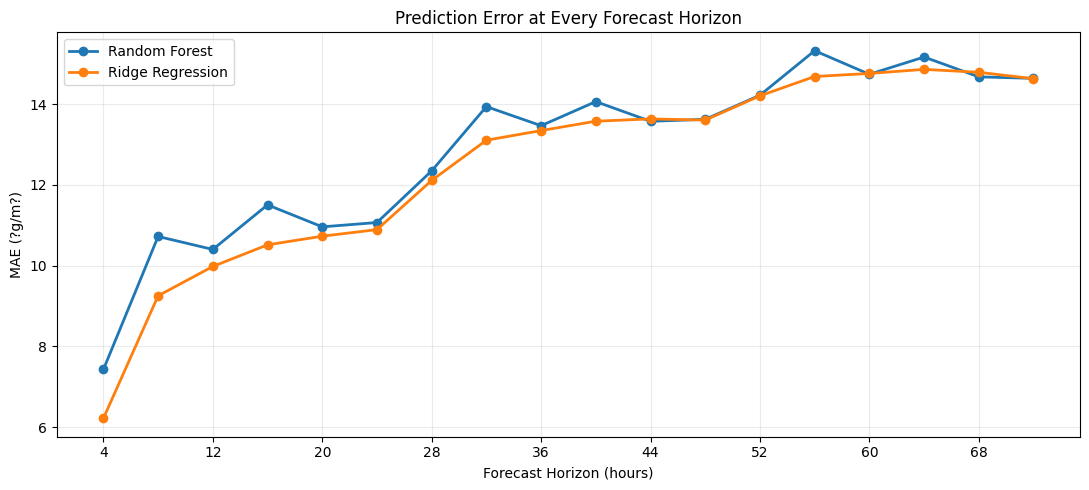

In [33]:
plt.figure(figsize=(11, 5))
for name, group in horizon_metrics.groupby('Model'):
    plt.plot(group['Horizon_hours'], group['MAE'], marker='o', linewidth=2, label=name)

plt.xlabel('Forecast Horizon (hours)')
plt.ylabel('MAE (?g/m?)')
plt.title('Prediction Error at Every Forecast Horizon')
plt.xticks(range(4, 73, 8))
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

## 9. RMSE and R2 graphs

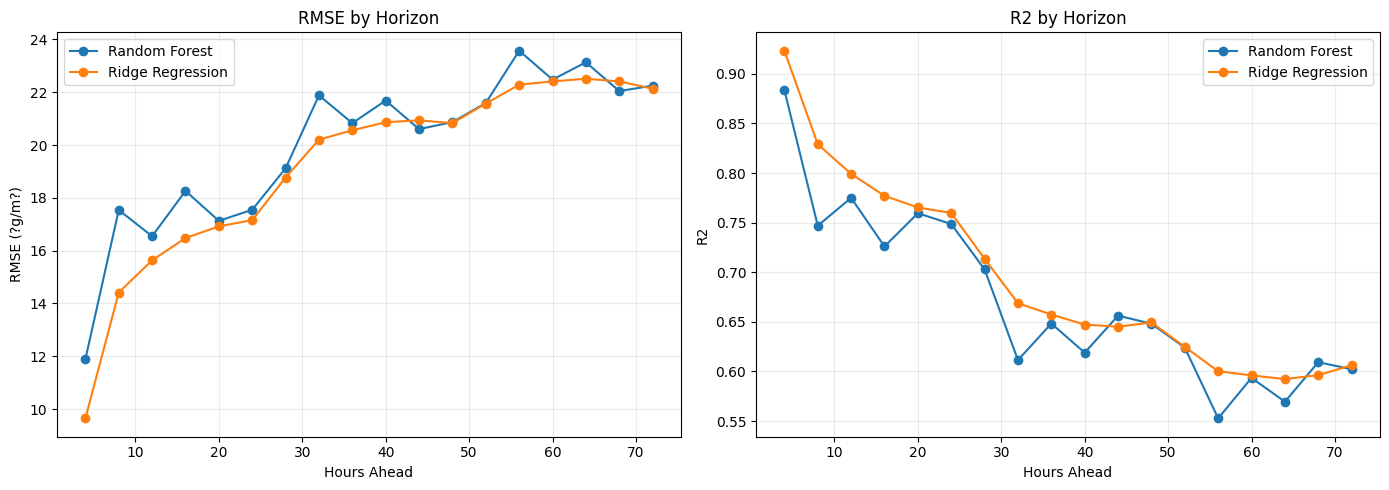

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, group in horizon_metrics.groupby('Model'):
    axes[0].plot(group['Horizon_hours'], group['RMSE'], marker='o', label=name)
    axes[1].plot(group['Horizon_hours'], group['R2'], marker='o', label=name)

axes[0].set(title='RMSE by Horizon', xlabel='Hours Ahead', ylabel='RMSE (?g/m?)')
axes[1].set(title='R2 by Horizon', xlabel='Hours Ahead', ylabel='R2')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.show()

## 10. Actual vs predicted values

Each dot represents one forecast. Points close to the diagonal are good predictions.

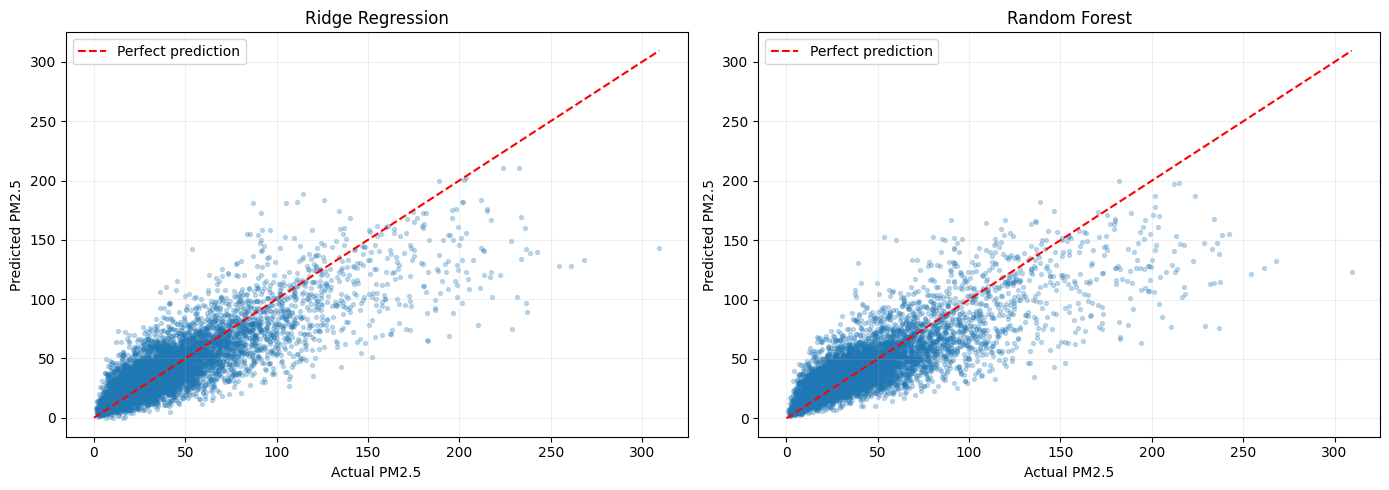

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, name, pred in [(axes[0], 'Ridge Regression', ridge_predictions),
                       (axes[1], 'Random Forest', rf_predictions)]:
    true_values = y_test.to_numpy().ravel()[::100]
    pred_values = pred.ravel()[::100]
    ax.scatter(true_values, pred_values, alpha=0.25, s=8)

    limit = max(true_values.max(), pred_values.max())
    ax.plot([0, limit], [0, limit], 'r--', label='Perfect prediction')
    ax.set(xlabel='Actual PM2.5', ylabel='Predicted PM2.5', title=name)
    ax.grid(alpha=0.20)
    ax.legend()

plt.tight_layout()
plt.show()

## 11. 72-hour example forecast

This graph compares actual PM2.5 with each model for one city at one test-time position.

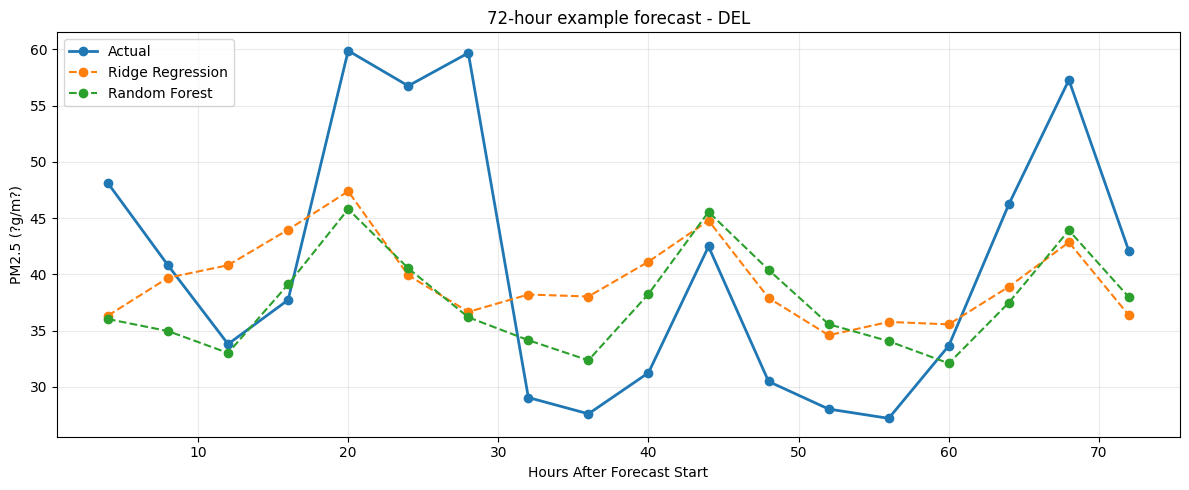

In [36]:
sample_city = 'DEL'
sample_mask = test['city_id'].values == sample_city
sample_positions = np.where(sample_mask)[0]

if len(sample_positions) == 0:
    sample_row = 0
    sample_city = test['city_id'].iloc[0]
else:
    sample_row = sample_positions[len(sample_positions) // 2]

hours = np.arange(4, 73, 4)
actual = y_test.iloc[sample_row].to_numpy()
ridge_example = ridge_predictions[sample_row]
rf_example = rf_predictions[sample_row]

plt.figure(figsize=(12, 5))
plt.plot(hours, actual, marker='o', linewidth=2, label='Actual')
plt.plot(hours, ridge_example, marker='o', linestyle='--', label='Ridge Regression')
plt.plot(hours, rf_example, marker='o', linestyle='--', label='Random Forest')
plt.xlabel('Hours After Forecast Start')
plt.ylabel('PM2.5 (?g/m?)')
plt.title(f'72-hour example forecast - {sample_city}')
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

## 12. Error by city

This shows whether one model works better in some cities than others.

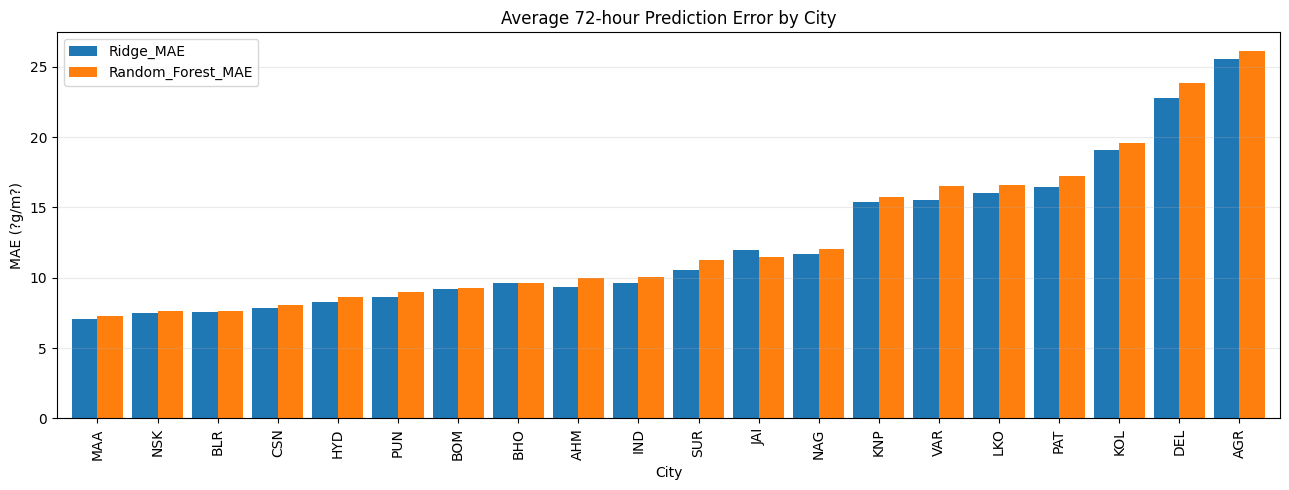

,City,Ridge_MAE,Random_Forest_MAE
13,MAA,7.079537,7.290839
15,NSK,7.506110,7.606464
3,BLR,7.563530,7.639041
5,CSN,7.880646,8.081458
7,HYD,8.252390,8.614347
17,PUN,8.667880,9.021651
4,BOM,9.199884,9.300554
2,BHO,9.612791,9.627457
1,AHM,9.376127,9.996215
8,IND,9.610671,10.022494


In [37]:
cities = test['city_id'].to_numpy()
city_rows = []

for city in sorted(np.unique(cities)):
    mask = cities == city
    if mask.sum() == 0:
        continue
    city_rows.append({
        'City': city,
        'Ridge_MAE': mean_absolute_error(y_test.to_numpy()[mask], ridge_predictions[mask]),
        'Random_Forest_MAE': mean_absolute_error(y_test.to_numpy()[mask], rf_predictions[mask])
    })

city_errors = pd.DataFrame(city_rows).sort_values('Random_Forest_MAE')

ax = city_errors.plot(x='City', y=['Ridge_MAE', 'Random_Forest_MAE'], kind='bar', figsize=(13, 5), width=0.85)
ax.set_xlabel('City')
ax.set_ylabel('MAE (?g/m?)')
ax.set_title('Average 72-hour Prediction Error by City')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

city_errors

## 13. Save evaluation tables

Only learning outputs are saved. No production model is changed.

In [38]:
OUTPUT_DIR = PROJECT_ROOT / 'notebooks' / 'outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

horizon_metrics.to_csv(OUTPUT_DIR / 'pm25_72h_horizon_metrics.csv', index=False)
city_errors.to_csv(OUTPUT_DIR / 'pm25_72h_city_errors.csv', index=False)

print('Saved horizon metrics:', OUTPUT_DIR / 'pm25_72h_horizon_metrics.csv')
print('Saved city errors:', OUTPUT_DIR / 'pm25_72h_city_errors.csv')

Saved horizon metrics: c:\Users\ANISH\OneDrive\Desktop\SEM 5\ML\cp\notebooks\outputs\pm25_72h_horizon_metrics.csv
Saved city errors: c:\Users\ANISH\OneDrive\Desktop\SEM 5\ML\cp\notebooks\outputs\pm25_72h_city_errors.csv
